## 1. Import libraries

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
path_train = "GiveMeSomeCredit.csv"

data= pd.read_csv(path_train)

print("shape", data.shape)
data.head(10)

shape (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
5,1,1.459344,54,F,3,3,1718.000000,NaN,18,9,0,7,0.0,2
6,1,14.540918,45,F,3,3,1.151865,3726.0,11,0,2,7,3.0,3
7,1,0.915053,48,M,2,1,0.652057,2600.0,8,0,1,7,0.0,3
8,1,1.000000,31,F,2,0,503.000000,NaN,4,7,0,7,0.0,2
9,0,1.445042,38,F,3,0,0.136132,4715.0,5,3,0,7,2.0,0


In [3]:
df=data.copy()

### 1.1 Quick check: duplicate rows

The file has no customer ID, so a repeated row could be two different customers with identical values. The count is checked and reported; the rows are kept because they are a tiny share of the data and cannot be proven to be errors.

In [4]:
dup = df.duplicated().sum()
print(f'Duplicated rows: {dup:,} ({dup / len(df):.2%} of {len(df):,}). Kept: no customer ID to prove they are errors.')

Duplicated rows: 142 (0.09% of 149,724). Kept: no customer ID to prove they are errors.


## 2. Data preparation

### 2.1 Target

`SeriousDlqin` is the target. About 6.6% of customers defaulted, so the classes are imbalanced and every default rate below should be read against that 6.6% baseline.

In [5]:
target = "SeriousDlqin"

print("Target:", target)
print("Unique values:")
print(df[target].unique())

Target: SeriousDlqin
Unique values:
[1 0]


In [6]:
target_summary = pd.DataFrame({
    "Count": df[target].value_counts(),
    "Percent": df[target].value_counts(normalize=True).mul(100).round(2)
})

target_summary

,Count,Percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


### 2.2 Target leakage

`NumberOfDefault` is positive exactly when the target is 1, so it is the outcome in disguise. It is removed before any analysis.

In [7]:
print(df[["NumberOfDefault", target]].head(20))

    NumberOfDefault  SeriousDlqin
0                 1             1
1                 0             0
2                 0             0
3                 2             1
4                 1             1
5                 2             1
6                 3             1
7                 3             1
8                 2             1
9                 0             0
10                0             0
11                0             0
12                0             0
13                0             0
14                3             1
15                1             1
16                2             1
17                0             0
18                2             1
19                2             1


In [8]:
df = df.drop(columns=["NumberOfDefault"])

print("Leaked feature removed.")

Leaked feature removed.


### 2.3 Impossible values

One customer is younger than 18 and thirteen are older than 100. These 14 rows are removed. No negative incomes or negative counts exist.

In [9]:
print("Age < 18:", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum())
print("MonthlyIncome < 0:", (df["MonthlyIncome"] < 0).sum())
print("NumberOfTimes90DaysLate < 0:", (df["NumberOfTimes90DaysLate"] < 0).sum())
print("NumberRealEstateLoansOrLines < 0:", (df["NumberRealEstateLoansOrLines"] < 0).sum())

Age < 18: 1
Age > 100: 13
MonthlyIncome < 0: 0
NumberOfTimes90DaysLate < 0: 0
NumberRealEstateLoansOrLines < 0: 0


In [10]:
df = df[(df["age"] >= 18) & (df["age"] <= 100)]

### 2.4 Train/test split

A stratified 70/30 split keeps the default rate at 6.6% in both parts. Everything that is learned from the data (medians, rates, bands) comes from the training set only.

In [11]:
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (104797, 12)
X_test : (44913, 12)
y_train: (104797,)
y_test : (44913,)


In [12]:
print("Overall:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nTrain:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Overall:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Train:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64

Test:
SeriousDlqin
0    93.4
1     6.6
Name: proportion, dtype: float64


In [13]:
train_df = X_train.copy()
train_df[target] = y_train

print("Train dataframe shape:", train_df.shape)
train_df.head()

Train dataframe shape: (104797, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
134668,0.203223,60,F,2,0,1600.000000,NaN,8,0,1,0,0.0,0
119703,1.000000,24,M,3,0,0.100074,1358.0,3,0,0,0,0.0,0
37115,0.200152,49,M,1,0,0.224416,12917.0,8,0,1,0,0.0,0
141624,0.025735,78,F,1,0,347.000000,NaN,7,0,0,0,0.0,0
139483,0.133169,29,M,3,0,723.000000,NaN,5,0,0,0,0.0,0


In [14]:
test_df = X_test.copy()
test_df[target] = y_test

print("Train dataframe shape:", test_df.shape)
test_df.head()

Train dataframe shape: (44913, 13)


,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,SeriousDlqin
76820,0.021663,61,F,3,0,0.500453,5516.0,8,0,2,0,0.0,0
135401,0.000000,62,F,3,0,1461.000000,NaN,14,0,1,0,0.0,0
5324,0.060561,39,F,3,0,0.198144,12500.0,8,0,1,1,2.0,0
90486,0.824374,30,M,2,0,0.100439,4330.0,4,0,0,0,0.0,0
43461,1.000000,41,F,1,0,0.023712,10500.0,1,0,1,0,2.0,1


### 2.5 Missing values

`MonthlyIncome` is missing for 19.8% of training customers and `NumberOfDependents` for 2.6%. The missingness is informative: customers without a reported income default less often (5.5% against 6.9%). For that reason a `MonthlyIncome_missing` flag is created before the median imputation, and the median is taken from the training set and reused for the test set.

In [15]:
missing_train = pd.DataFrame({
    "Missing_Count": train_df.isnull().sum(),
    "Missing_Percent": (
        train_df.isnull().mean().mul(100).round(2)
    )
})

missing_train = missing_train.sort_values(
    "Missing_Percent",
    ascending=False
)

missing_train

,Missing_Count,Missing_Percent
MonthlyIncome,20723,19.77
NumberOfDependents,2767,2.64
SEX,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
EDUCATION,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
DebtRatio,0,0.00
NumberOfTimes90DaysLate,0,0.00


In [16]:
train_df.groupby(
    train_df["MonthlyIncome"].isna()
)["SeriousDlqin"].mean()

MonthlyIncome
False    0.068761
True     0.054722
Name: SeriousDlqin, dtype: float64

In [17]:
train_df.groupby(
    train_df["NumberOfDependents"].isna()
)["SeriousDlqin"].mean()

NumberOfDependents
False    0.066627
True     0.042284
Name: SeriousDlqin, dtype: float64

In [18]:
train_df["MonthlyIncome_missing"] = (
    train_df["MonthlyIncome"].isna().astype(int)
)

test_df["MonthlyIncome_missing"] = (
    test_df["MonthlyIncome"].isna().astype(int)
)

In [19]:
income_median = train_df["MonthlyIncome"].median()

train_df["MonthlyIncome"] = train_df["MonthlyIncome"].fillna(
    income_median
)

test_df["MonthlyIncome"] = test_df["MonthlyIncome"].fillna(
    income_median
)

In [20]:
dependents_median = train_df["NumberOfDependents"].median()

train_df["NumberOfDependents"] = train_df[
    "NumberOfDependents"
].fillna(dependents_median)

test_df["NumberOfDependents"] = test_df[
    "NumberOfDependents"
].fillna(dependents_median)

### 2.6 Engineered feature

`TotalPastDue` adds up the number of times a customer was 30-59, 60-89 and 90+ days late. The three delay counts describe the same behaviour, so one combined count is easier to interpret.

In [21]:
train_df["TotalPastDue"] = (
    train_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + train_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + train_df["NumberOfTimes90DaysLate"]
)

train_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
134668,0,0,0,0
119703,0,0,0,0
37115,0,0,0,0
141624,0,0,0,0
139483,0,0,0,0


In [22]:
test_df["TotalPastDue"] = (
    test_df["NumberOfTime30-59DaysPastDueNotWorse"]
    + test_df["NumberOfTime60-89DaysPastDueNotWorse"]
    + test_df["NumberOfTimes90DaysLate"]
)

test_df[[
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "TotalPastDue"
]].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue
76820,0,0,0,0
135401,0,0,0,0
5324,0,1,0,1
90486,0,0,0,0
43461,0,0,0,0


## 3. Feature distribution analysis

**Role:** data scientist at a lender. **Goal:** understand how important features are distributed and how they differ between customers who defaulted (`SeriousDlqin = 1`) and customers who did not.

Four features are investigated (the assignment asks for at least three), each with a different kind of problem:

| Feature | Why it is interesting |
|---|---|
| `RevolvingUtilizationOfUnsecuredLines` | extreme skew and impossible values |
| `age` | an almost symmetric, clean feature |
| `MonthlyIncome` | skewed and about 20% missing |
| `NumberOfTimes90DaysLate` | zero-inflated count |

All numbers come from the training set (`train_df`). The test set is used once, to confirm the utilisation pattern, and never to choose features. No model is trained.

In [23]:
sns.set_theme(style='whitegrid')
CLASS_COLORS = {0: '#4C78A8', 1: '#E45756'}
CLASS_NAMES = {0: 'No default', 1: 'Default'}
R = 'RevolvingUtilizationOfUnsecuredLines'

known_income = train_df.loc[train_df['MonthlyIncome_missing'] == 0]

def default_rate_table(groups):
    t = train_df.groupby(groups, observed=True)[target].agg(Customers='size', Defaults='sum', Default_rate='mean')
    t['Default_rate'] = (t['Default_rate'] * 100).round(1)
    return t

overall_rate = train_df[target].mean() * 100
print(f'Training customers: {len(train_df):,} | defaults: {int(train_df[target].sum()):,} | overall default rate: {overall_rate:.1f}%')

Training customers: 104,797 | defaults: 6,915 | overall default rate: 6.6%


### Overview: shape of the four features and the first difference between the groups

In [24]:
profile_inputs = {
    'age': train_df['age'],
    R: train_df[R],
    'MonthlyIncome (observed values only)': known_income['MonthlyIncome'],
    'NumberOfTimes90DaysLate': train_df['NumberOfTimes90DaysLate'],
}
missing_pct = {'MonthlyIncome (observed values only)': train_df['MonthlyIncome_missing'].mean() * 100}

rows = []
for name, s in profile_inputs.items():
    y_s = train_df.loc[s.index, target]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    rows.append({
        'Feature': name,
        'Skewness': s.skew(),
        '% zeros': (s == 0).mean() * 100,
        '% missing (before imputation)': missing_pct.get(name, 0.0),
        '% IQR outliers': ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100,
        '99th percentile': s.quantile(0.99),
        'Max': s.max(),
        'Median | no default': s[y_s == 0].median(),
        'Median | default': s[y_s == 1].median(),
        'Mean | no default': s[y_s == 0].mean(),
        'Mean | default': s[y_s == 1].mean(),
    })
profile = pd.DataFrame(rows).set_index('Feature').round(2)
profile.T

Feature,age,RevolvingUtilizationOfUnsecuredLines,MonthlyIncome (observed values only),NumberOfTimes90DaysLate
Skewness,0.19,60.37,88.59,9.12
% zeros,0.00,7.27,1.35,94.61
% missing (before imputation),0.00,0.00,19.77,0.00
% IQR outliers,0.02,0.52,3.95,5.39
99th percentile,87.00,1.09,25000.00,2.00
Max,99.00,22198.00,1794060.00,15.00
Median | no default,52.00,0.13,5500.00,0.00
Median | default,46.00,0.83,4500.00,0.00
Mean | no default,52.79,6.19,6705.11,0.05
Mean | default,46.06,6.00,5689.76,0.67


Skewness near 0 means a symmetric distribution; values far above 0 mean a long right tail. `age` (about 0.2) is nearly symmetric, while utilisation and income are extremely right-skewed, so **their means are dominated by a few extreme values** and the medians are the better summary.

### Feature 1 · Revolving utilisation (`RevolvingUtilizationOfUnsecuredLines`)

Balance on credit cards and personal lines divided by the credit limit. A sensible value is between 0 (nothing used) and 1 (limit fully used).

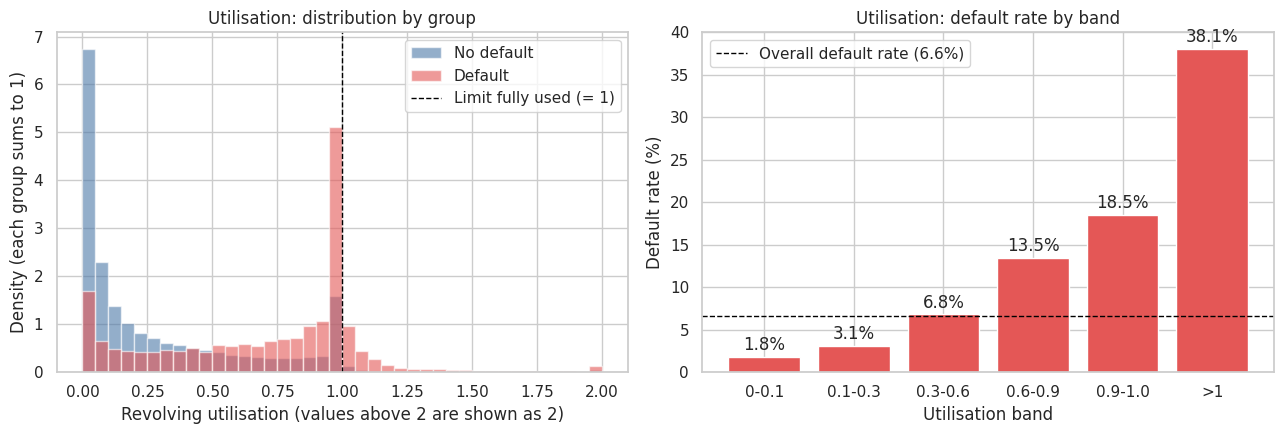

Utilisation above 1: 2,306 customers (2.2%) -> default rate 38.1%
Utilisation up to 1: default rate 5.9%
Largest value in the data: 22,198  (a utilisation of 22,198 times the limit is not plausible)


,Customers,Defaults,Default_rate
RevolvingUtilizationOfUnsecuredLines,,,
0-0.1,45133,808,1.8
0.1-0.3,19886,619,3.1
0.3-0.6,15281,1035,6.8
0.6-0.9,10625,1435,13.5
0.9-1.0,11566,2140,18.5
>1,2306,878,38.1


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(0, 2, 41)
for k in (0, 1):
    axes[0].hist(train_df.loc[train_df[target] == k, R].clip(upper=2), bins=bins, density=True,
                 alpha=0.6, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
axes[0].axvline(1, color='black', ls='--', lw=1, label='Limit fully used (= 1)')
axes[0].set(xlabel='Revolving utilisation (values above 2 are shown as 2)',
            ylabel='Density (each group sums to 1)', title='Utilisation: distribution by group')
axes[0].legend()

util_band = pd.cut(train_df[R], [-0.001, 0.1, 0.3, 0.6, 0.9, 1.0, np.inf],
                   labels=['0-0.1', '0.1-0.3', '0.3-0.6', '0.6-0.9', '0.9-1.0', '>1'])
util_table = default_rate_table(util_band)
bars = axes[1].bar(util_table.index.astype(str), util_table['Default_rate'], color='#E45756')
axes[1].bar_label(bars, fmt='%.1f%%', padding=2)
axes[1].axhline(overall_rate, color='black', ls='--', lw=1, label=f'Overall default rate ({overall_rate:.1f}%)')
axes[1].set(xlabel='Utilisation band', ylabel='Default rate (%)', title='Utilisation: default rate by band')
axes[1].legend()
plt.tight_layout()
plt.show()

over = train_df[R] > 1
print(f'Utilisation above 1: {over.sum():,} customers ({over.mean():.1%}) -> default rate {train_df.loc[over, target].mean():.1%}')
print(f'Utilisation up to 1: default rate {train_df.loc[~over, target].mean():.1%}')
print(f'Largest value in the data: {train_df[R].max():,.0f}  (a utilisation of 22,198 times the limit is not plausible)')
util_table

**Reading it**

- *Shape:* extremely right-skewed. Most customers are between 0 and 1, but a few values are enormous (the maximum is above 22,000), which is not plausible for a ratio of balance to limit. Probably data errors or tiny credit limits. About 7% of customers have exactly 0.
- *Difference between the groups:* the non-defaulters are concentrated near low utilisation (median 0.13) while defaulters are shifted to the right (median 0.83), with a clear spike at exactly 1, i.e. customers who have used their whole limit.
- *Evidence:* the default rate climbs steadily from **1.8%** (utilisation below 0.1) to **18.5%** (0.9-1.0) and **38.1%** for customers above their limit, against an overall rate of 6.6%.
- *Credit-risk explanation:* a borrower who uses almost the whole limit has no liquidity buffer and probably depends on credit to cover ordinary expenses, so any shock (lost income, an unexpected bill) leads to missed payments. Above 1 the borrower is over the limit, which is a strong distress signal.
- *Treatment idea:* cap (winsorise) at about 1-2 or at a high percentile, and keep a flag for "over limit".
- *Mean versus median:* average utilisation is 6.19 among non-defaulters and 6.00 among defaulters, the reverse of what the medians (0.13 and 0.83) show. A handful of extreme values drive the average, so medians and banded default rates give the fairer picture.

**Check on unseen customers.** The bands were defined without looking at the test set. If the default rate per band is similar in the test set, the pattern is not an artefact of the training sample.

In [26]:
test_util_band = pd.cut(test_df[R], [-0.001, 0.1, 0.3, 0.6, 0.9, 1.0, np.inf], labels=list(util_table.index))
test_rate = test_df.groupby(test_util_band, observed=True)[target].mean().mul(100).round(1)
pd.DataFrame({'Train default rate (%)': util_table['Default_rate'], 'Test default rate (%)': test_rate})

,Train default rate (%),Test default rate (%)
RevolvingUtilizationOfUnsecuredLines,,
0-0.1,1.8,1.9
0.1-0.3,3.1,3.2
0.3-0.6,6.8,6.5
0.6-0.9,13.5,12.8
0.9-1.0,18.5,19.6
>1,38.1,35.4


### Feature 2 · Age

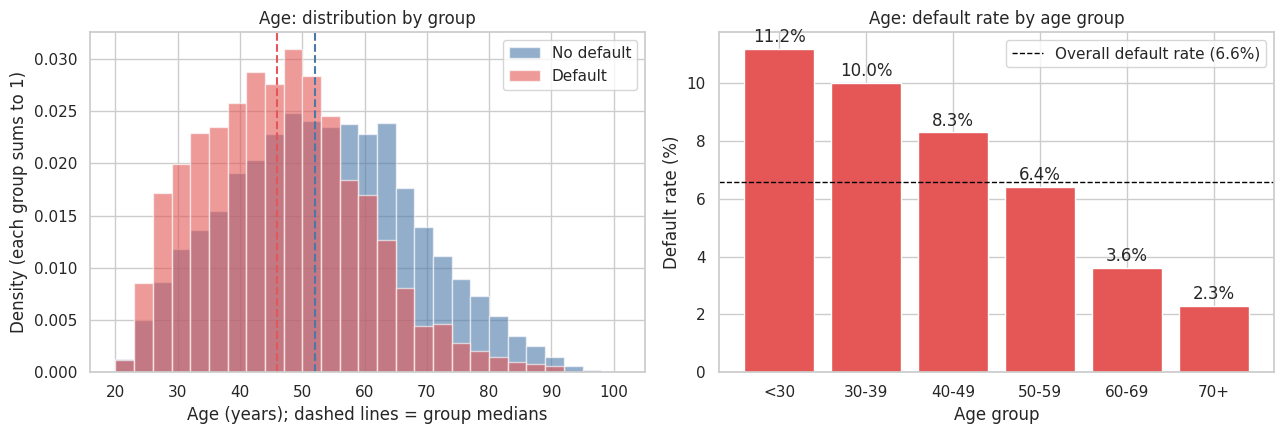

              mean  median
SeriousDlqin              
No default    52.8    52.0
Default       46.1    46.0


,Customers,Defaults,Default_rate
age,,,
<30,6103,682,11.2
30-39,16157,1610,10.0
40-49,23946,1992,8.3
50-59,24736,1592,6.4
60-69,20305,723,3.6
70+,13550,316,2.3


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.arange(20, 102, 3)
for k in (0, 1):
    vals = train_df.loc[train_df[target] == k, 'age']
    axes[0].hist(vals, bins=bins, density=True, alpha=0.6, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
    axes[0].axvline(vals.median(), color=CLASS_COLORS[k], ls='--', lw=1.5)
axes[0].set(xlabel='Age (years); dashed lines = group medians', ylabel='Density (each group sums to 1)',
            title='Age: distribution by group')
axes[0].legend()

age_band = pd.cut(train_df['age'], [17, 29, 39, 49, 59, 69, 100], labels=['<30', '30-39', '40-49', '50-59', '60-69', '70+'])
age_table = default_rate_table(age_band)
bars = axes[1].bar(age_table.index.astype(str), age_table['Default_rate'], color='#E45756')
axes[1].bar_label(bars, fmt='%.1f%%', padding=2)
axes[1].axhline(overall_rate, color='black', ls='--', lw=1, label=f'Overall default rate ({overall_rate:.1f}%)')
axes[1].set(xlabel='Age group', ylabel='Default rate (%)', title='Age: default rate by age group')
axes[1].legend()
plt.tight_layout()
plt.show()

print(train_df.groupby(target)['age'].agg(['mean', 'median']).round(1).rename(index=CLASS_NAMES))
age_table

**Reading it**

- *Shape:* close to symmetric (skewness about 0.2), roughly bell-shaped, no missing values and practically no outliers (0.02% by the IQR rule) after the 18-100 filter applied earlier in the notebook. This is the cleanest of the four features.
- *Difference between the groups:* defaulters are younger: mean age **46.1 vs 52.8** years (median 46 vs 52).
- *Evidence:* the default rate falls monotonically with age, from **11.2%** for customers under 30 to **2.3%** for customers aged 70+, a nearly five-fold difference.
- *Credit-risk explanation:* younger borrowers usually have shorter credit histories, lower and less stable income and less savings. Older borrowers tend to have stable income, accumulated assets and a stronger habit of repaying.
- *Caution:* in many jurisdictions age may not be used directly in an approval decision, so it needs a regulatory check before being used in production.
- *Overlap:* the age histograms of the two groups overlap a lot, so age is a weak separator on its own (single-feature AUC 0.63). Customers under 30 default about 4.9 times as often as customers aged 70+, yet most of them still repay.

### Feature 3 · Monthly income

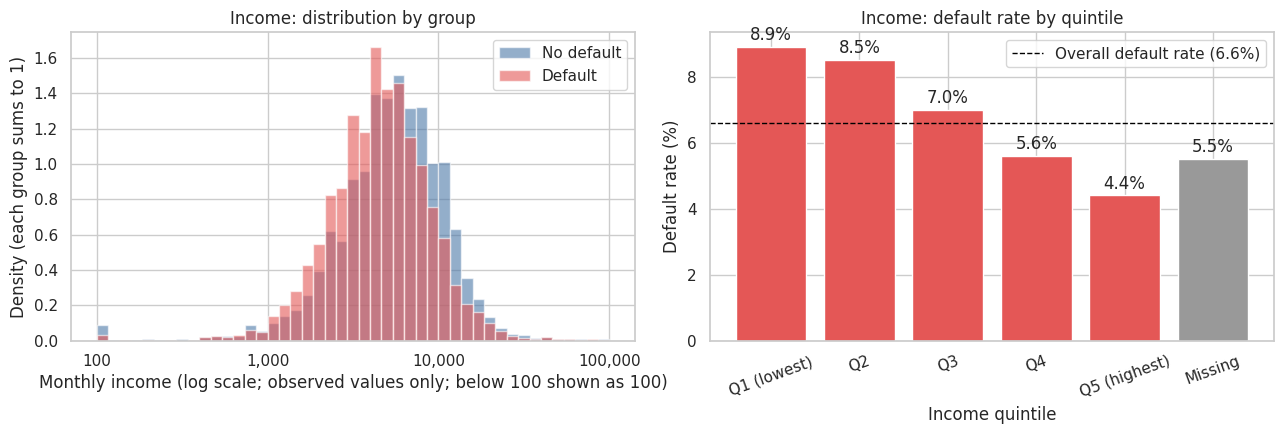

Quintile edges: ['0', '3,000', '4,583', '6,344', '9,136', '1,794,060']
Missing income: 19.8% of customers, default rate 5.5% vs 6.9% when income is known
DebtRatio median: 1,173.0 (income missing) vs 0.30 (income known)
Share with DebtRatio > 1: 94.1% (income missing) vs 5.9% (income known)


,Customers,Defaults,Default_rate
Q1 (lowest),17467,1553,8.9
Q2,16373,1389,8.5
Q3,16604,1155,7.0
Q4,16815,941,5.6
Q5 (highest),16815,743,4.4
Missing,20723,1134,5.5


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pos = known_income[known_income['MonthlyIncome'] > 0]
bins = np.linspace(2, 5, 46)
for k in (0, 1):
    vals = np.log10(pos.loc[pos[target] == k, 'MonthlyIncome']).clip(2, 5)
    axes[0].hist(vals, bins=bins, density=True, alpha=0.6, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
axes[0].set_xticks([2, 3, 4, 5])
axes[0].set_xticklabels(['100', '1,000', '10,000', '100,000'])
axes[0].set(xlabel='Monthly income (log scale; observed values only; below 100 shown as 100)', ylabel='Density (each group sums to 1)',
            title='Income: distribution by group')
axes[0].legend()

labels = ['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)']
income_band = pd.Series('Missing', index=train_df.index, dtype='object')
income_band.loc[known_income.index] = pd.qcut(known_income['MonthlyIncome'], 5, labels=labels).astype(str)
income_table = default_rate_table(income_band).loc[labels + ['Missing']]
colors = ['#E45756'] * 5 + ['#999999']
bars = axes[1].bar(income_table.index, income_table['Default_rate'], color=colors)
axes[1].bar_label(bars, fmt='%.1f%%', padding=2)
axes[1].axhline(overall_rate, color='black', ls='--', lw=1, label=f'Overall default rate ({overall_rate:.1f}%)')
axes[1].set(xlabel='Income quintile', ylabel='Default rate (%)', title='Income: default rate by quintile')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend()
plt.tight_layout()
plt.show()

edges = pd.qcut(known_income['MonthlyIncome'], 5, retbins=True)[1]
print('Quintile edges:', [f'{e:,.0f}' for e in edges])
print(f"Missing income: {train_df['MonthlyIncome_missing'].mean():.1%} of customers, default rate "
      f"{train_df.loc[train_df['MonthlyIncome_missing'] == 1, target].mean():.1%} vs "
      f"{train_df.loc[train_df['MonthlyIncome_missing'] == 0, target].mean():.1%} when income is known")
miss = train_df['MonthlyIncome_missing'] == 1
print(f"DebtRatio median: {train_df.loc[miss, 'DebtRatio'].median():,.1f} (income missing) vs "
      f"{train_df.loc[~miss, 'DebtRatio'].median():.2f} (income known)")
print(f"Share with DebtRatio > 1: {(train_df.loc[miss, 'DebtRatio'] > 1).mean():.1%} (income missing) vs "
      f"{(train_df.loc[~miss, 'DebtRatio'] > 1).mean():.1%} (income known)")
income_table

**Reading it**

- *Shape:* very right-skewed (skewness about 89): the median income is 5,416 but the maximum is 1.79 million, so the mean is pulled up by a few very high earners. On a log scale the distribution is much closer to bell-shaped. There are also 1,136 observed incomes of exactly 0.
- *Missing values:* **19.8%** of customers have no income. Missingness is **not random**: they default less often (**5.5%** vs 6.9%), and for them `DebtRatio` is not a real ratio (median above 1,000, above 1 for 94% of them). This is why the notebook keeps the `MonthlyIncome_missing` flag together with the median imputation.
- *Difference between the groups:* median income **5,500 for non-defaulters vs 4,500 for defaulters**.
- *Evidence:* the default rate falls from **8.9%** in the lowest income fifth to **4.4%** in the highest. The effect is real but much weaker than for utilisation or past-due history.
- *Credit-risk explanation:* lower income means a smaller capacity to absorb shocks and to service debt, but income alone says little about willingness to repay, which is why the signal is moderate.

**Income reporting status.** A recorded income of exactly 0 is not the same as no income being recorded. The table separates customers with a positive income, a recorded zero and a missing value (imputed values are not counted as recorded).

In [29]:
income_status = np.select(
    [train_df['MonthlyIncome_missing'] == 1, train_df['MonthlyIncome'] == 0],
    ['Missing', 'Recorded zero'],
    default='Recorded positive')
default_rate_table(pd.Series(income_status, index=train_df.index, name='Income status'))

,Customers,Defaults,Default_rate
Income status,,,
Missing,20723,1134,5.5
Recorded positive,82938,5729,6.9
Recorded zero,1136,52,4.6


### Feature 4 · Times 90+ days late (`NumberOfTimes90DaysLate`)

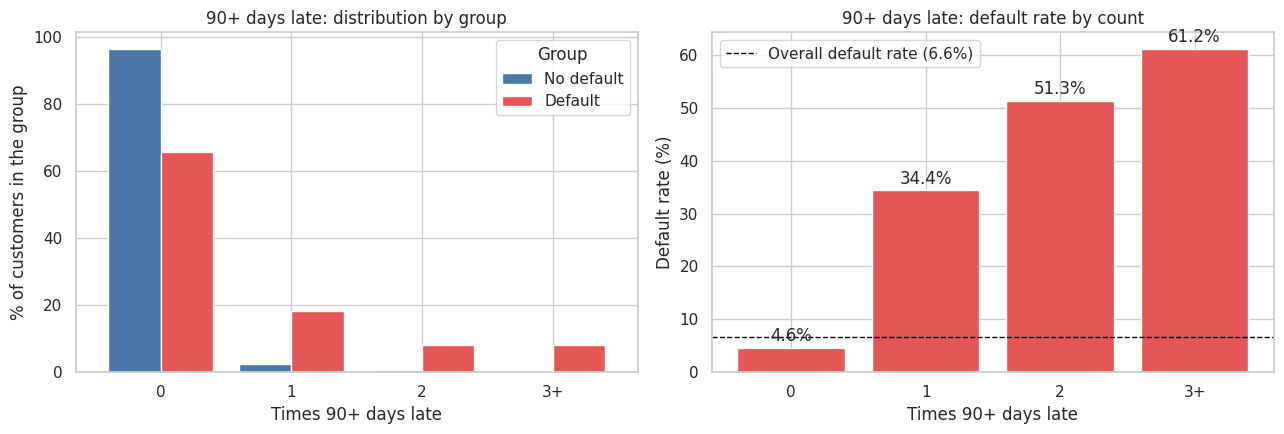

Customers with zero 90-day delays: 94.6%
At least one 90-day delay: 34.3% of defaulters vs 3.4% of non-defaulters


,Customers,Defaults,Default_rate
NumberOfTimes90DaysLate,,,
0,99145,4546,4.6
1,3656,1256,34.4
2,1092,560,51.3
3+,904,553,61.2


In [30]:
late_band = train_df['NumberOfTimes90DaysLate'].clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'})
order = ['0', '1', '2', '3+']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

share = (pd.crosstab(late_band, train_df[target], normalize='columns') * 100).loc[order].rename(columns=CLASS_NAMES)
share.plot.bar(ax=axes[0], color=[CLASS_COLORS[0], CLASS_COLORS[1]], width=0.8)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Group')
axes[0].set(xlabel='Times 90+ days late', ylabel='% of customers in the group',
            title='90+ days late: distribution by group')

late_table = default_rate_table(late_band).loc[order]
bars = axes[1].bar(late_table.index, late_table['Default_rate'], color='#E45756')
axes[1].bar_label(bars, fmt='%.1f%%', padding=2)
axes[1].axhline(overall_rate, color='black', ls='--', lw=1, label=f'Overall default rate ({overall_rate:.1f}%)')
axes[1].set(xlabel='Times 90+ days late', ylabel='Default rate (%)', title='90+ days late: default rate by count')
axes[1].legend()
plt.tight_layout()
plt.show()

late = train_df['NumberOfTimes90DaysLate'] > 0
print(f'Customers with zero 90-day delays: {(~late).mean():.1%}')
print(f"At least one 90-day delay: {late[train_df[target] == 1].mean():.1%} of defaulters vs {late[train_df[target] == 0].mean():.1%} of non-defaulters")
late_table

**Reading it**

- *Shape:* **zero-inflated** and right-skewed: **94.6%** of customers have never been 90+ days late; the rest are spread over 1 to 15 delays (skewness about 9). A histogram of the raw values is useless, so I grouped the counts into 0, 1, 2 and 3+.
- *Difference between the groups:* **34.3% of defaulters** have at least one 90-day delay, but only **3.4% of non-defaulters**. The mean count is 0.67 vs 0.05.
- *Evidence:* the default rate is **4.6%** with no delay, but **34.4%** after one, **51.3%** after two and **61.2%** after three or more.
- *Credit-risk explanation:* past repayment behaviour is the best predictor of future behaviour. A 90-day delay is a serious sign that the borrower cannot or will not pay, and it often comes before an actual default.
- *Coverage:* 65.7% of defaulters (4,546 of 6,915) have no 90-day delay on record, so this count cannot flag every default by itself. For customers with at least one delay the default rate is 41.9% (2,369 of 5,652); with three or more delays it is roughly 13 times the rate of customers with none.

## 4. Final insights

All numeric candidates are ranked with two measures computed on the training set: the AUC of each feature alone (0.5 means no information) and its information value (IV, on deciles). The same cell also tests the combined delay count `TotalPastDue` and shows the default rate by number of past-due events.

Two things stand out in the ranking: utilisation (0.777) and the combined delay count `TotalPastDue` (0.778) are clearly the strongest, and the 30-59 day count (0.689) is a better single separator than the 90+ day count (0.656). The 90+ day count is still the clearest *severity* signal (default rate 4.6% to 61.2%), but the repayment-history feature to carry forward is the combined count, which includes it.

In [31]:
candidates = ['age', R, 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
              'NumberRealEstateLoansOrLines', 'NumberOfTime30-59DaysPastDueNotWorse',
              'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'TotalPastDue']

def information_value(x, y, q=10):
    bins = pd.qcut(x, q=q, duplicates='drop')
    if bins.nunique() < 4:
        bins = x.clip(upper=3)
    tab = pd.crosstab(bins, y)
    good, bad = tab[0] / tab[0].sum(), tab[1] / tab[1].sum()
    return ((good - bad) * np.log(good / bad)).replace([np.inf, -np.inf], np.nan).sum()

rows = []
for c in candidates:
    auc = roc_auc_score(train_df[target], train_df[c])
    rows.append({
        'Feature': c,
        'AUC (one feature alone)': max(auc, 1 - auc),
        'Direction': 'higher = riskier' if auc >= 0.5 else 'higher = safer',
        'IV': information_value(train_df[c], train_df[target]),
        'Missing % in raw file': data[c].isna().mean() * 100 if c in data.columns else 0.0,
    })
ranking = pd.DataFrame(rows).sort_values('AUC (one feature alone)', ascending=False).set_index('Feature').round(3)
display(ranking)

chosen = [R, 'TotalPastDue', 'age']
display(train_df[chosen].corr(method='spearman').round(2))

display(default_rate_table(train_df['TotalPastDue'].clip(upper=4).map({0: '0', 1: '1', 2: '2', 3: '3', 4: '4+'})))

,AUC (one feature alone),Direction,IV,Missing % in raw file
Feature,,,,
TotalPastDue,0.778,higher = riskier,1.442,0.000
RevolvingUtilizationOfUnsecuredLines,0.777,higher = riskier,1.103,0.000
NumberOfTime30-59DaysPastDueNotWorse,0.689,higher = riskier,0.751,0.000
NumberOfTimes90DaysLate,0.656,higher = riskier,0.875,0.000
age,0.634,higher = safer,0.259,0.000
NumberOfTime60-89DaysPastDueNotWorse,0.617,higher = riskier,0.573,0.000
MonthlyIncome,0.569,higher = safer,0.072,19.774
NumberOfDependents,0.551,higher = riskier,0.038,2.600
NumberOfOpenCreditLinesAndLoans,0.541,higher = safer,0.059,0.000


,RevolvingUtilizationOfUnsecuredLines,TotalPastDue,age
RevolvingUtilizationOfUnsecuredLines,1.00,0.29,-0.27
TotalPastDue,0.29,1.00,-0.12
age,-0.27,-0.12,1.00


,Customers,Defaults,Default_rate
TotalPastDue,,,
0,83858,2234,2.7
1,11946,1492,12.5
2,4116,987,24.0
3,2054,729,35.5
4+,2823,1473,52.2


**Overlap between the three chosen features.** Spearman correlations show whether utilisation, past-due history (`TotalPastDue`) and age carry different information. All correlations are weak (at most 0.29 in absolute value), so the three features are largely complementary.

In [32]:
final_three = [R, 'TotalPastDue', 'age']
train_df[final_three].corr(method='spearman').round(2)

,RevolvingUtilizationOfUnsecuredLines,TotalPastDue,age
RevolvingUtilizationOfUnsecuredLines,1.00,0.29,-0.27
TotalPastDue,0.29,1.00,-0.12
age,-0.27,-0.12,1.00


### Summary of findings

| Feature | Shape and data quality | Difference between the groups | Credit-risk reading |
|---|---|---|---|
| Revolving utilisation | extreme right skew, 7.3% zeros, maximum 22,198 (not a plausible ratio) | median 0.83 (default) against 0.13 (no default); default rate 1.8% below 0.1 and 38.1% above 1 | little liquidity buffer left, so any shock leads to missed payments |
| Age | nearly symmetric, complete | median 46 against 52; default rate 11.2% under 30 and 2.3% at 70+ | shorter credit history and less stable income when young |
| Monthly income | extreme right skew, 19.8% missing (not at random) | median 4,500 against 5,500; default rate 8.9% in the lowest fifth and 4.4% in the highest | lower capacity to absorb shocks, but a moderate signal |
| 90+ days late | zero-inflated, 94.6% zeros | 34.3% of defaulters against 3.4% of non-defaulters had at least one delay (so 65.7% of defaulters had none); default rate 4.6% with none and 61.2% with three or more | past repayment behaviour predicts future behaviour |

### Answer

I would start with **revolving utilisation**, **past-due history** and **age**. Utilisation (AUC 0.78) shows how stretched a borrower is today. Past-due history, best captured by the total number of late payments (`TotalPastDue`, AUC 0.78) and led by the 90+ day delays (default rate 4.6% with none against 61.2% with three or more), shows how the borrower has actually repaid. Age (AUC 0.63) is complete and easy to explain and is only weakly related to the other two (Spearman -0.27 and -0.12). Monthly income (AUC 0.57, 20% missing) and `DebtRatio` (AUC 0.53, not a real ratio when income is missing) were left out because they are weaker and messier.

### Notes

- All patterns are associations, not causal effects.
- The analysis is exploratory: no model was trained and the test set was not used to choose features.
- `TotalPastDue` (AUC 0.78, IV 1.44) is chosen over the 90+ day count alone (AUC 0.66, IV 0.88) because it is stronger and still easy to explain.
- Age may not be usable in an approval decision in some jurisdictions, so it would need a regulatory check before production use.
- The raw CSV was never modified.